In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.concat([pd.read_csv("final.csv")], ignore_index=True)
df = df[df["instance"] == "parallel"]
solvers_to_remove = [
    "ilp_arc_95",
    "ilp_arc_heuristic_placement",
    "ilp_arc_heuristic_warm_start",
    "ilp_arc_rl_warm_start",
]
df = df[~df["solver"].isin(solvers_to_remove)]
df.reset_index(drop=True, inplace=True)
df.head()

,instance,solver,users,neighbors,groups,score,runtime,buildtime
0,parallel,ilp_arc,40,1,4,280.0,17.532892,11.569892
1,parallel,ilp_arc,40,1,4,280.0,16.447927,10.207434
2,parallel,heuristic,40,1,4,80.0,4.281108,0.000000
3,parallel,PPO,40,1,4,216.0,67.875395,0.000000
4,parallel,ilp_arc,60,1,4,420.0,47.449175,27.530304


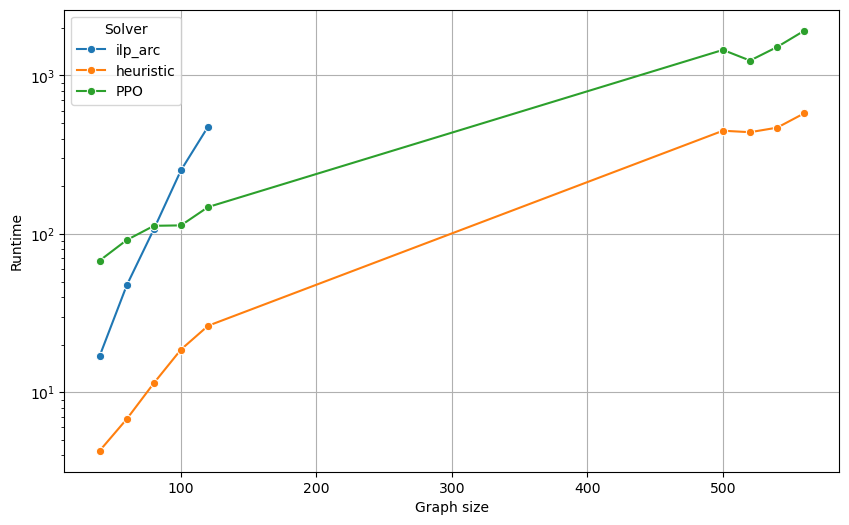

In [3]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="users", y="runtime", hue="solver", marker="o")
# plt.title("Runtime vs Users for Different Solvers")
plt.xlabel("Graph size")
plt.ylabel("Runtime")
plt.yscale("log")
plt.legend(title="Solver")
plt.grid(True)
plt.show()

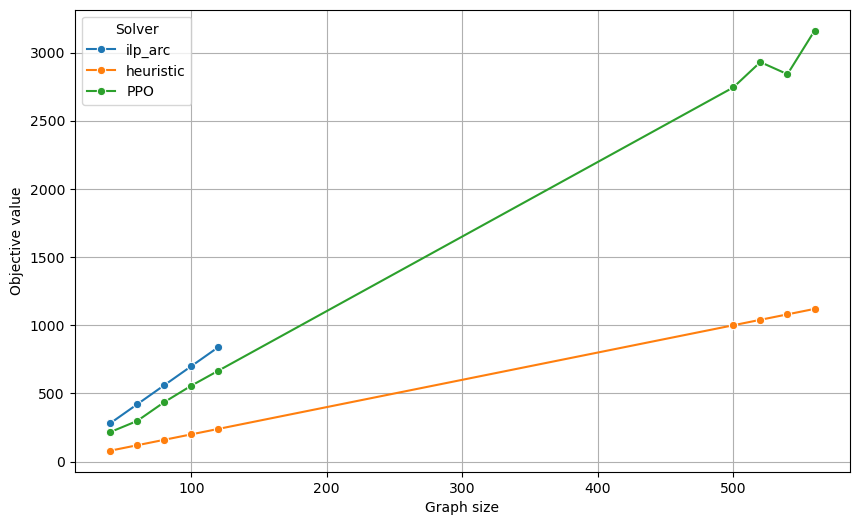

In [4]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="users", y="score", hue="solver", marker="o")
# plt.title("Runtime vs Users for Different Solvers")
plt.xlabel("Graph size")
plt.ylabel("Objective value")
# plt.yscale("log")
plt.legend(title="Solver")
plt.grid(True)
plt.show()

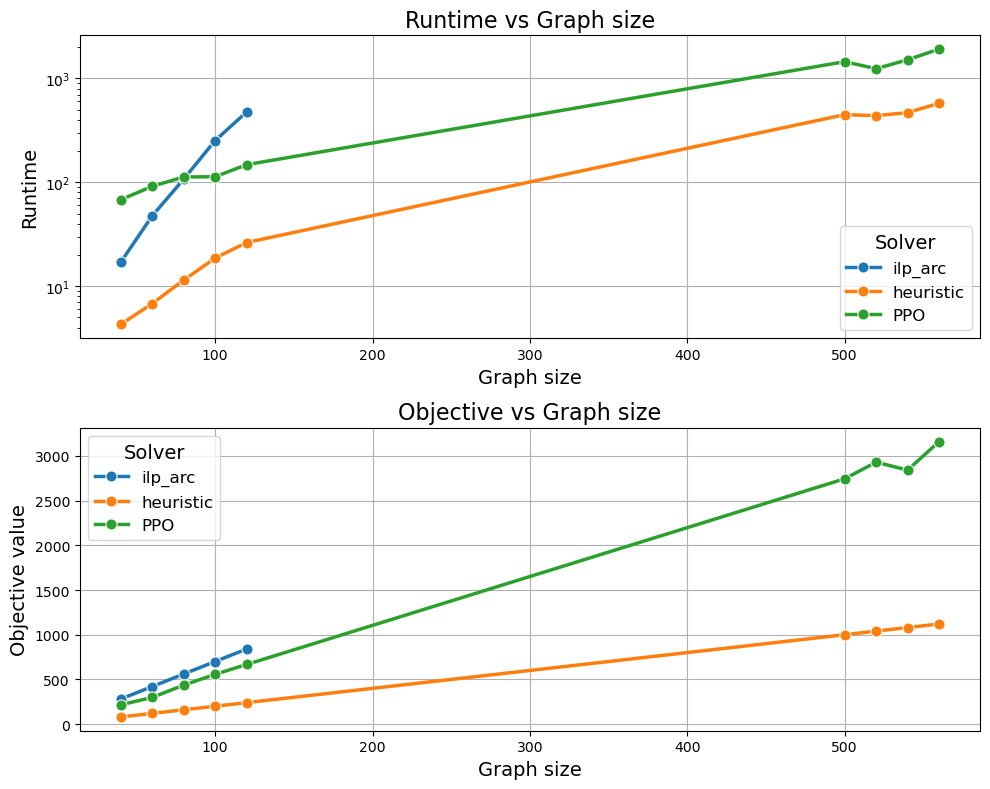

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Common parameters for the plots
common_params = {
    'data': df,
    'x': 'users',
    'hue': 'solver',
    'marker': 'o',
    'linewidth': 2.5,  # Thicker lines
    'markersize': 8,   # Larger markers
    'ax': None
}

# Plot runtime vs users
common_params['ax'] = axes[0]
sns.lineplot(y='runtime', **common_params)
axes[0].set_title("Runtime vs Graph size", fontsize=16)
axes[0].set_xlabel("Graph size", fontsize=14)
axes[0].set_ylabel("Runtime", fontsize=14)
axes[0].set_yscale("log")
axes[0].legend(title="Solver", fontsize=12, title_fontsize=14)
axes[0].grid(True)

# Plot score vs users
common_params['ax'] = axes[1]
sns.lineplot(y='score', **common_params)
axes[1].set_title("Objective vs Graph size", fontsize=16)
axes[1].set_xlabel("Graph size", fontsize=14)
axes[1].set_ylabel("Objective value", fontsize=14)
axes[1].legend(title="Solver", fontsize=12, title_fontsize=14)
axes[1].grid(True)
axes[1].grid(True)

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('final_star.pdf', bbox_inches='tight')
plt.show()